# Phase 3: Historical membership evaluation

At each month end, the strategy ranks stocks using the prior trading day's close and historical S&P 500 membership as of that same prior day. It then assumes execution at the month-end close. The signal cannot use that closing price. Transaction costs apply to buys and sells. Data comes from a community-reconstructed historical membership and adjusted prices, including former constituents; data and execution assumptions still require independent verification.

The earlier current-constituent results were biased and are superseded. Historical fundamentals are not used.


In [1]:
from pathlib import Path
import sys
from functools import partial
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
root = Path.cwd()
if not (root / "src").is_dir(): root = root.parent
if not (root / "src/backtest.py").exists(): raise FileNotFoundError("Open from the project or notebooks folder")
sys.path.insert(0, str(root))
from src.backtest import run_factor_backtest, point_in_time_momentum_score
from src.data_loader import load_historical_prices, load_historical_membership, constituents_as_of
from src.metrics import calculate_performance_metrics
data = root / "data/sp500_historical_2018_2024"
prices = load_historical_prices(data / "prices_long.parquet")
membership = load_historical_membership(data / "members.parquet")
score = partial(point_in_time_momentum_score, membership=membership, lookback=252)
print(f"Prices: {prices.index.min().date()} to {prices.index.max().date()}; {len(prices.columns)} historical symbols")


Prices: 2018-01-02 to 2024-12-31; 633 historical symbols


## Costs and position sizing

All runs select the five highest-momentum historical constituents at each formation, using the prior trading close. Scores require 253 consecutive observed prices through the signal date. At the formation close, weights are equal or based on volatility available through the prior close. Costs of 0, 5, 10 and 25 basis points apply to buys and sells. Missing selected holding-period returns stop the backtest.


In [2]:
runs = {}
for weighting in ["equal", "inverse_volatility"]:
    for bps in [0, 5, 10, 25]:
        r, holdings, trades = run_factor_backtest(prices, score, top_n=5, transaction_cost_bps=bps, weighting=weighting, volatility_lag=1)
        runs[(weighting, bps)] = (r, holdings, trades)
for weighting in ["equal", "inverse_volatility"]:
    final = [float((1 + runs[(weighting, b)][0]).prod()) for b in [0, 5, 10, 25]]
    assert all(a >= b for a, b in zip(final, final[1:]))
    for b in [5, 10, 25]:
        assert runs[(weighting, b)][1]["holdings"].equals(runs[(weighting, 0)][1]["holdings"])
rows = []
for (weighting, bps), (r, _, trades) in runs.items():
    rows.append({"Weighting": weighting, "Cost (bps/side)": bps, **calculate_performance_metrics(r).to_dict(), "Ending $1": (1+r).prod(), "Mean monthly traded value": trades.gross_traded_value.mean()})
comparison = pd.DataFrame(rows).set_index(["Weighting", "Cost (bps/side)"])
comparison.round(4)

CAGR  Annual Return  Annual Volatility  \
Weighting          Cost (bps/side)                                             
equal              0                0.2210         0.2506             0.3159   
                   5                0.2154         0.2459             0.3158   
                   10               0.2099         0.2413             0.3157   
                   25               0.1933         0.2272             0.3155   
inverse_volatility 0                0.1895         0.2238             0.3140   
                   5                0.1835         0.2187             0.3139   
                   10               0.1776         0.2136             0.3138   
                   25               0.1599         0.1983             0.3135   

                                    Sharpe Ratio  Max Drawdown  Ending $1  \
Weighting          Cost (bps/side)                                          
equal              0                      0.7934       -0.2651     3.2592   
                   5                      0.7788       -0.2666     3.1718   
                   10                     0.7642       -0.2681     3.0867   
                   25                     0.7203       -0.2725     2.8449   
inverse_volatility 0                      0.7128       -0.2936     2.7919   
                   5                      0.6967       -0.2952     2.7100   
                   10                     0.6806       -0.2968     2.6304   
                   25                     0.6323       -0.3028     2.4056   

                                    Mean monthly traded value  
Weighting          Cost (bps/side)                             
equal              0                                   0.7655  
                   5                                   0.7654  
                   10                                  0.7653  
                   25                                  0.7649  
inverse_volatility 0                                   0.8389  
                   5                                   0.8387  
                   10                                  0.8385  
                   25                                  0.8380

## SPY comparison on matching dates

SPY adjusted-close data is downloaded on execution. This cell does not save data. Adjusted prices include distributions under the provider's adjustment method. The strategy and SPY returns below share the same monthly dates.

In [3]:
strategy = runs[("equal", 10)][0]
start = runs[("equal", 10)][2].formation_date.iloc[0]
spy = yf.download("SPY", start=start.strftime("%Y-%m-%d"), end=(strategy.index[-1] + pd.Timedelta(days=3)).strftime("%Y-%m-%d"), auto_adjust=True, progress=False)
if spy.empty: raise RuntimeError("SPY download failed; rerun when data access is available.")
close = spy["Close"]["SPY"] if isinstance(spy.columns, pd.MultiIndex) else spy["Close"]
monthly = close.resample("ME").last()
spy_returns = monthly.pct_change(fill_method=None).reindex(strategy.index)
if spy_returns.isna().any(): raise ValueError("Missing SPY observations on strategy dates")
common = pd.concat([runs[("equal",0)][0].rename("Momentum gross"), strategy.rename("Momentum 10 bps"), spy_returns.rename("SPY")], axis=1).dropna()
assert len(common) == len(strategy)
pd.DataFrame({col: calculate_performance_metrics(common[col]) for col in common}).T.round(4)

,CAGR,Annual Return,Annual Volatility,Sharpe Ratio,Max Drawdown
Momentum gross,0.2210,0.2506,0.3159,0.7934,-0.2651
Momentum 10 bps,0.2099,0.2413,0.3157,0.7642,-0.2681
SPY,0.1583,0.1627,0.1730,0.9404,-0.2393


## Rolling 12-month results

Rolling return compounds 12 monthly returns. Rolling volatility annualizes the standard deviation of those monthly returns. Rolling drawdown measures the largest loss from a prior peak within each window, starting with $1.

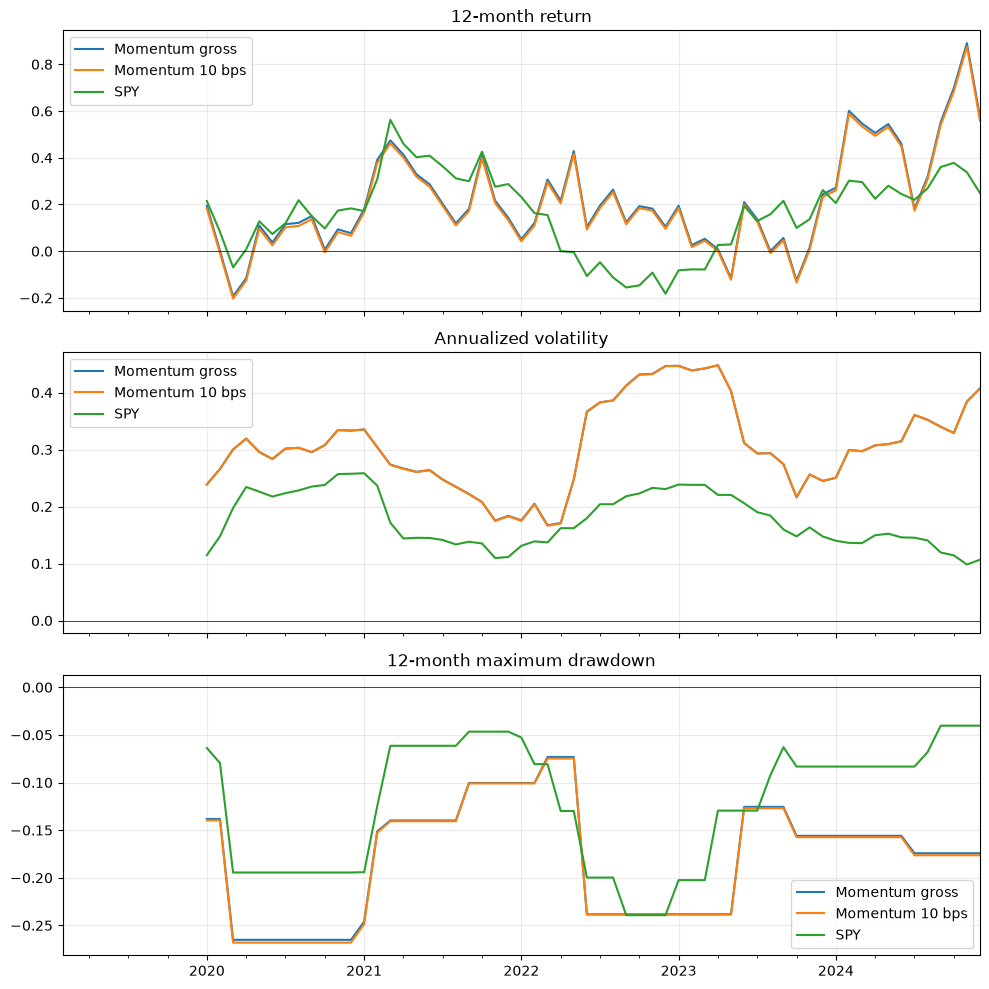

In [4]:
def window_drawdown(r):
    wealth = np.r_[1.0, np.cumprod(1 + np.asarray(r))]
    return np.min(wealth / np.maximum.accumulate(wealth) - 1)
rolling_return = (1 + common).rolling(12).apply(np.prod, raw=True) - 1
rolling_vol = common.rolling(12).std() * np.sqrt(12)
rolling_drawdown = common.rolling(12).apply(window_drawdown, raw=True)
fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
for data, title, ax in zip([rolling_return, rolling_vol, rolling_drawdown], ["12-month return", "Annualized volatility", "12-month maximum drawdown"], axes):
    data.plot(ax=ax, title=title); ax.axhline(0, color="black", linewidth=0.5); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

## Chronological Phase 4 holdout setup

The table below is a preliminary dataset for development, not a trained model. Each row is a historical index member at the formation date; features use past prices, and the label is next-month return. Development ends in November 2021; December 2021 is purged; the model holdout begins January 2022. Since Phase 3 results for the holdout years have already been inspected, use a later evaluation period for a truly fresh final study. Reconstructed membership, adjusted prices, ticker changes, and missing data still require checks.


In [5]:
monthly_prices = prices.resample("ME").last(skipna=False)
momentum = prices.pct_change(252, fill_method=None).where(prices.notna().rolling(253, min_periods=253).sum().eq(253)).shift(1).resample("ME").last(skipna=False)
volatility = prices.pct_change(fill_method=None).rolling(252, min_periods=252).std().shift(1).resample("ME").last(skipna=False) * np.sqrt(252)
forward = monthly_prices.shift(-1).div(monthly_prices).sub(1)
def long(frame, name):
    return frame.rename_axis(index="formation_date", columns="ticker").stack().rename(name)
features = pd.concat([long(momentum, "momentum_252d"), long(volatility, "volatility_252d"), long(forward, "next_month_return")], axis=1).dropna()
# Only include members known at each formation date; no current-constituent filter.
member_dates = features.index.get_level_values("formation_date")
member_tickers = features.index.get_level_values("ticker")
monthly_members = {date: set(constituents_as_of(membership, prices.loc[:date].index[-2])) for date in member_dates.unique()}
features = features.loc[[ticker in monthly_members[date] for date, ticker in zip(member_dates, member_tickers)]]
# Purge December 2021, whose label ends during January 2022.
train = features.loc[features.index.get_level_values("formation_date") < "2021-12-01"].copy()
holdout = features.loc[features.index.get_level_values("formation_date") >= "2022-01-01"].copy()
assert train.index.get_level_values("formation_date").max() < pd.Timestamp("2021-12-01")
assert holdout.index.get_level_values("formation_date").min() >= pd.Timestamp("2022-01-01")
print(f"Development: {len(train)} rows; holdout: {len(holdout)} rows")
print("Development through", train.index.get_level_values("formation_date").max().date(), "| Holdout from", holdout.index.get_level_values("formation_date").min().date())
train.head()

Development: 17562 rows; holdout: 17525 rows
Development through 2021-11-30 | Holdout from 2022-01-31


momentum_252d  volatility_252d  next_month_return
formation_date ticker                                                   
2019-01-31     A            0.021670         0.277211           0.044576
               AAL         -0.303411         0.418556          -0.001217
               AAP          0.296386         0.322404           0.016206
               AAPL        -0.001376         0.316616           0.044771
               ABBV        -0.324917         0.337596          -0.013078